In [5]:
import mne

In [1]:
base_path = "D:/Users/windows/Desktop/EEG Inner Speech Decoding/Dataset/"

In [2]:
# subject, session 설정
subject = 'sub-01'
session = 'ses-01'

In [3]:
file_path = f"{base_path}/{subject}/{session}/eeg/{subject}_{session}_task-innerspeech_eeg-epo.fif"

In [6]:
epochs = mne.read_epochs(file_path)

Reading D:\Users\windows\Desktop\EEG Inner Speech Decoding\Dataset\sub-01\ses-01\eeg\sub-01_ses-01_task-innerspeech_eeg-epo.fif ...
    Found the data of interest:
        t =       0.00 ...    4500.00 ms
        0 CTF compensation matrices available
Not setting metadata
54 matching events found
No baseline correction applied
0 projection items activated


In [7]:
print(epochs)

<EpochsFIF | 54 events (all good), 0 – 4.5 s (baseline off), ~60.9 MiB, data loaded,
 'arriba': 12
 'abajo': 14
 'derecha': 11
 'izquierda': 17>


In [8]:
print(f"Epochs shape: {epochs.get_data().shape}")

Epochs shape: (54, 129, 1144)


In [9]:
print(epochs.info['ch_names'])

['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8', 'A9', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19', 'A20', 'A21', 'A22', 'A23', 'A24', 'A25', 'A26', 'A27', 'A28', 'A29', 'A30', 'A31', 'A32', 'B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B9', 'B10', 'B11', 'B12', 'B13', 'B14', 'B15', 'B16', 'B17', 'B18', 'B19', 'B20', 'B21', 'B22', 'B23', 'B24', 'B25', 'B26', 'B27', 'B28', 'B29', 'B30', 'B31', 'B32', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'C15', 'C16', 'C17', 'C18', 'C19', 'C20', 'C21', 'C22', 'C23', 'C24', 'C25', 'C26', 'C27', 'C28', 'C29', 'C30', 'C31', 'C32', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'D16', 'D17', 'D18', 'D19', 'D20', 'D21', 'D22', 'D23', 'D24', 'D25', 'D26', 'D27', 'D28', 'D29', 'D30', 'D31', 'D32', 'Status']


5가지 frequency bands로 filtering

In [10]:
# Delta band (0.5 - 4 Hz)
delta_epochs = epochs.copy().filter(l_freq=0.5, h_freq=4)

Setting up band-pass filter from 0.5 - 4 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 4.00 Hz
- Upper transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 5.00 Hz)
- Filter length: 1677 samples (6.602 s)



C:\Users\windows\AppData\Local\Temp\ipykernel_31292\4183109761.py:2: RuntimeWarning: filter_length (1677) is longer than the signal (1144), distortion is likely. Reduce filter length or filter a longer signal.
  delta_epochs = epochs.copy().filter(l_freq=0.5, h_freq=4)
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done 6912 out of 6912 | elapsed:    7.1s finished


Using matplotlib as 2D backend.


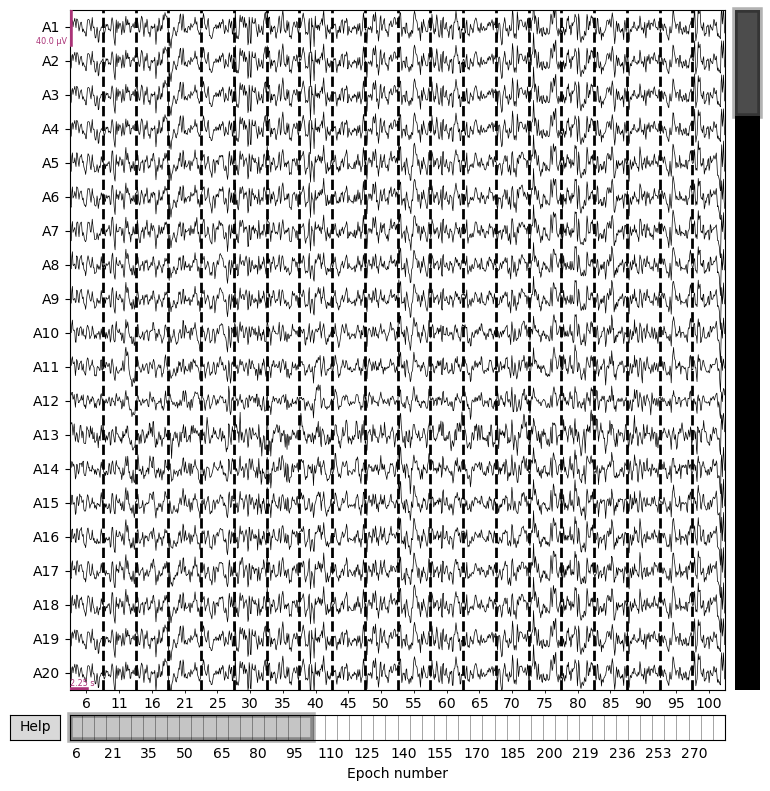

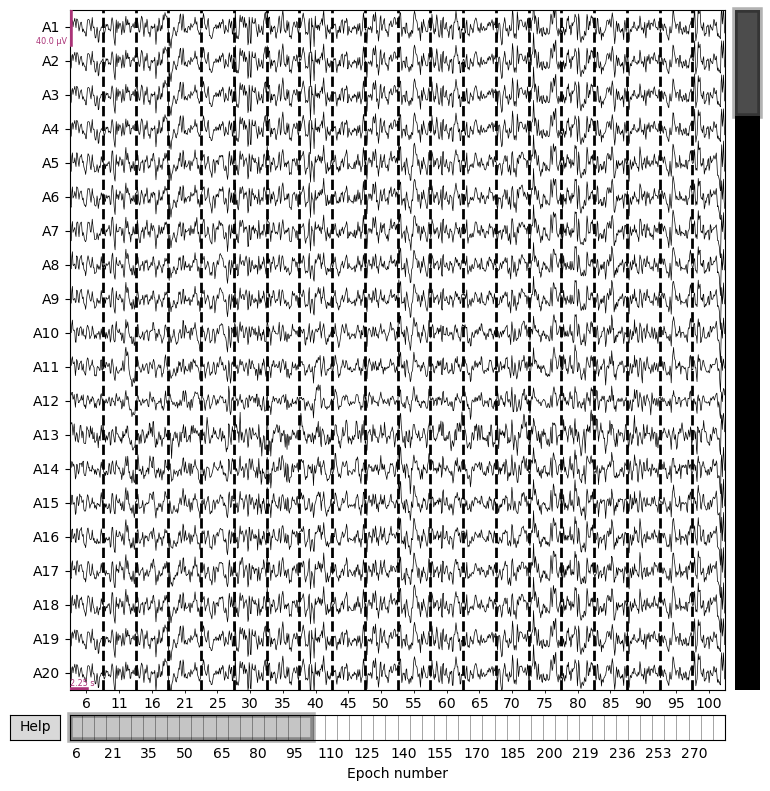

In [14]:
delta_epochs.plot(title="Delta Band (0.5 - 4 Hz)")

In [11]:
# Theta band (4 - 8 Hz)
theta_epochs = epochs.copy().filter(l_freq=4, h_freq=8)

Setting up band-pass filter from 4 - 8 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 4.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 3.00 Hz)
- Upper passband edge: 8.00 Hz
- Upper transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 9.00 Hz)
- Filter length: 421 samples (1.657 s)



[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done 6912 out of 6912 | elapsed:    7.0s finished


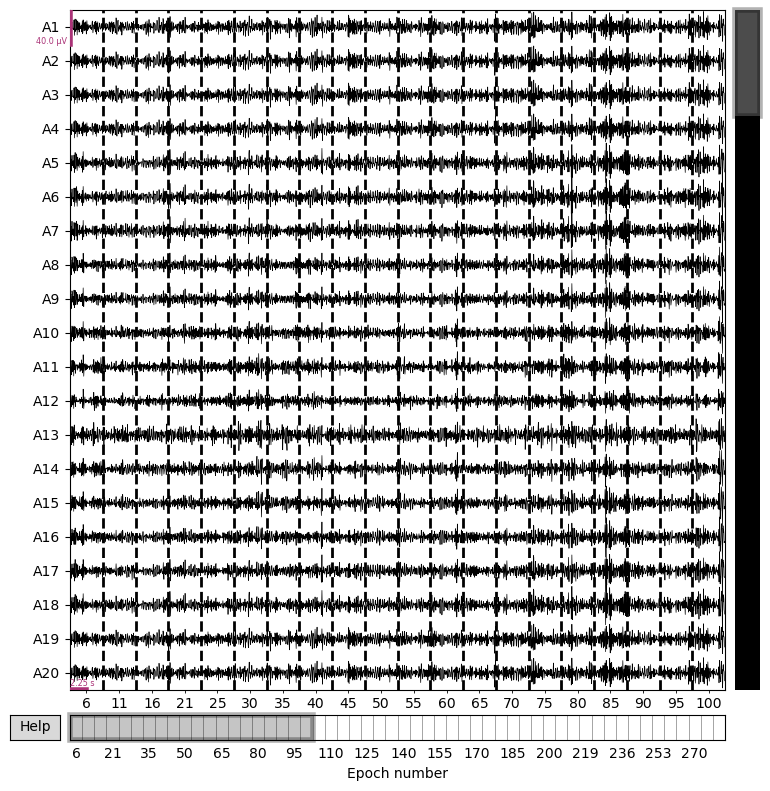

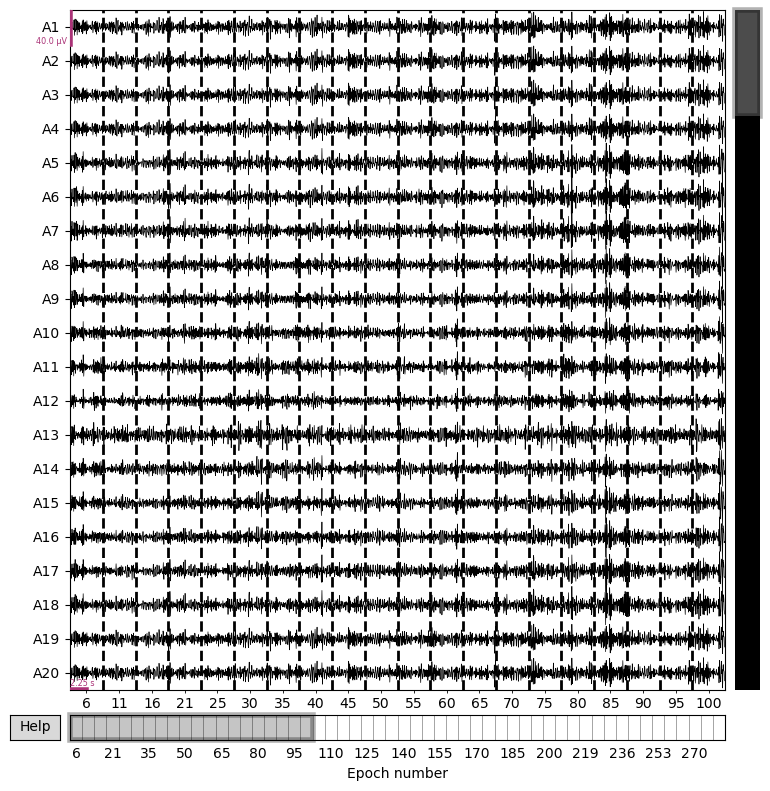

In [15]:
theta_epochs.plot(title="Theta Band (4 - 8 Hz)")

In [12]:
# Alpha band (8 - 13 Hz)
alpha_epochs = epochs.copy().filter(l_freq=8, h_freq=13)

Setting up band-pass filter from 8 - 13 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 8.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 7.00 Hz)
- Upper passband edge: 13.00 Hz
- Upper transition bandwidth: 3.25 Hz (-6 dB cutoff frequency: 14.62 Hz)
- Filter length: 421 samples (1.657 s)



[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done 6912 out of 6912 | elapsed:    7.0s finished


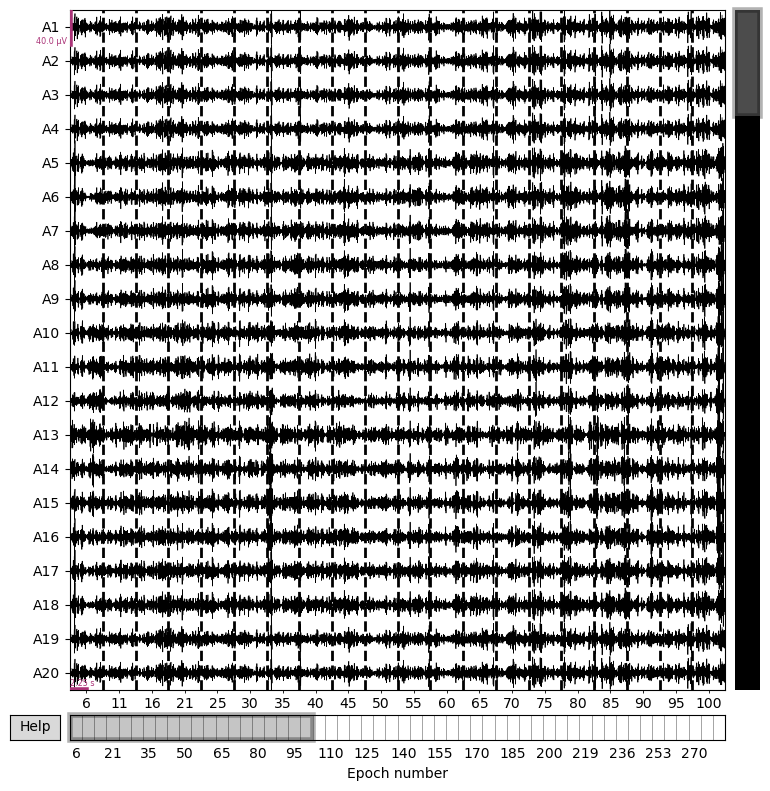

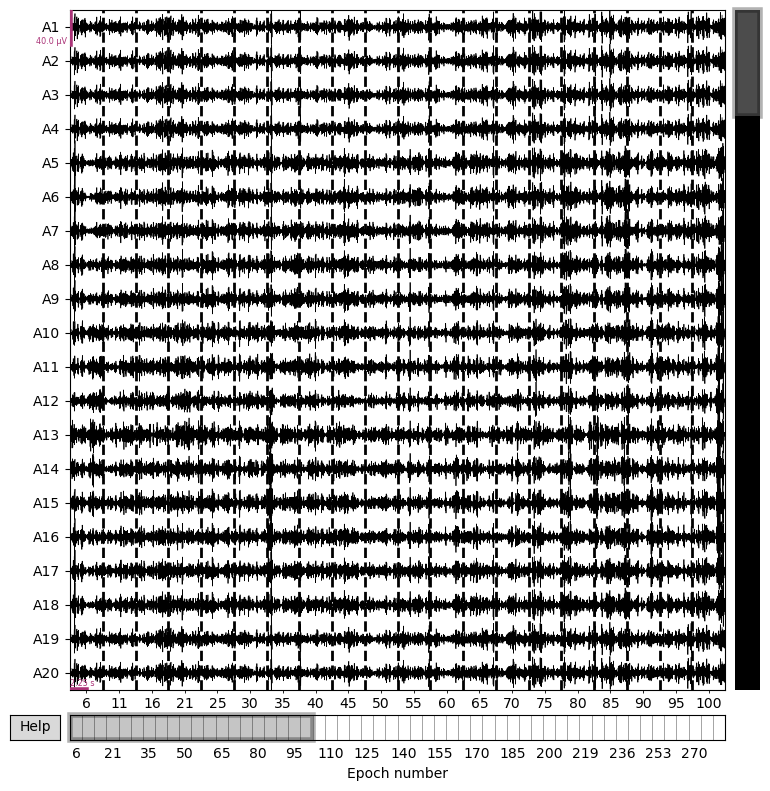

In [16]:
alpha_epochs.plot(title="Alpha Band (8 - 13 Hz)")

In [13]:
# Beta band (13-30 Hz)
beta_epochs = epochs.copy().filter(l_freq=13, h_freq=30)

Setting up band-pass filter from 13 - 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 13.00
- Lower transition bandwidth: 3.25 Hz (-6 dB cutoff frequency: 11.38 Hz)
- Upper passband edge: 30.00 Hz
- Upper transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 33.75 Hz)
- Filter length: 259 samples (1.020 s)



[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done 6912 out of 6912 | elapsed:    4.5s finished


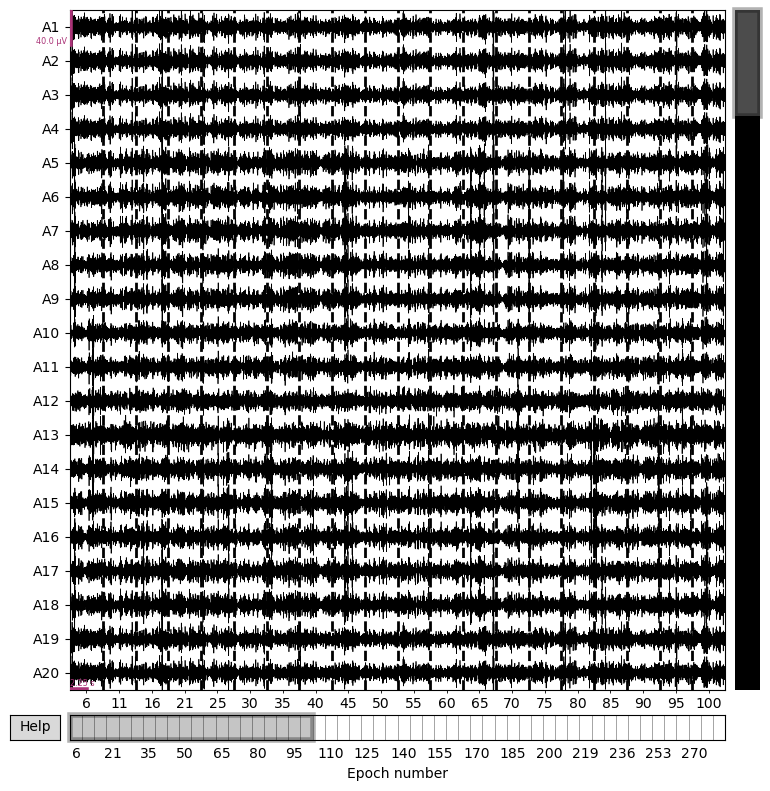

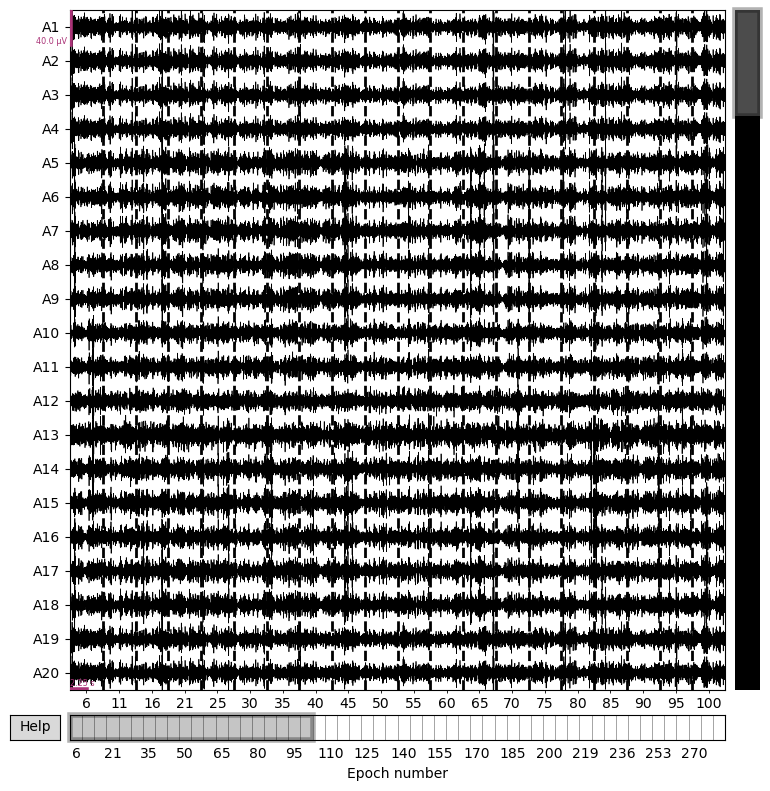

In [17]:
beta_epochs.plot(title="Beta Band (13 - 30 Hz)")

In [18]:
# Gamma band (30-100 Hz)
gamma_epochs = epochs.copy().filter(l_freq=30, h_freq=100)

Setting up band-pass filter from 30 - 1e+02 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 30.00
- Lower transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 26.25 Hz)
- Upper passband edge: 100.00 Hz
- Upper transition bandwidth: 25.00 Hz (-6 dB cutoff frequency: 112.50 Hz)
- Filter length: 113 samples (0.445 s)



[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done 6912 out of 6912 | elapsed:    6.7s finished


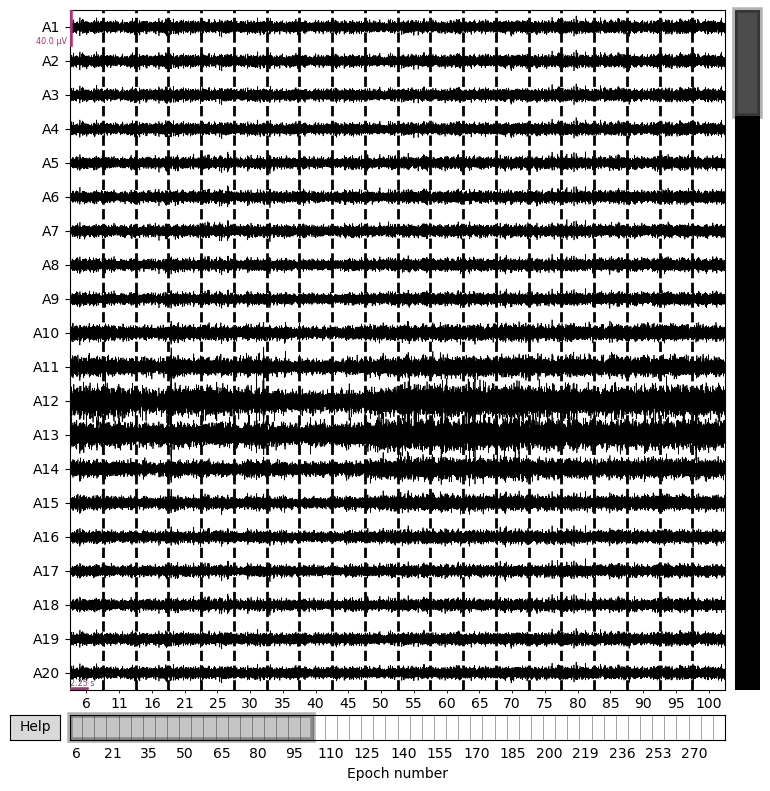

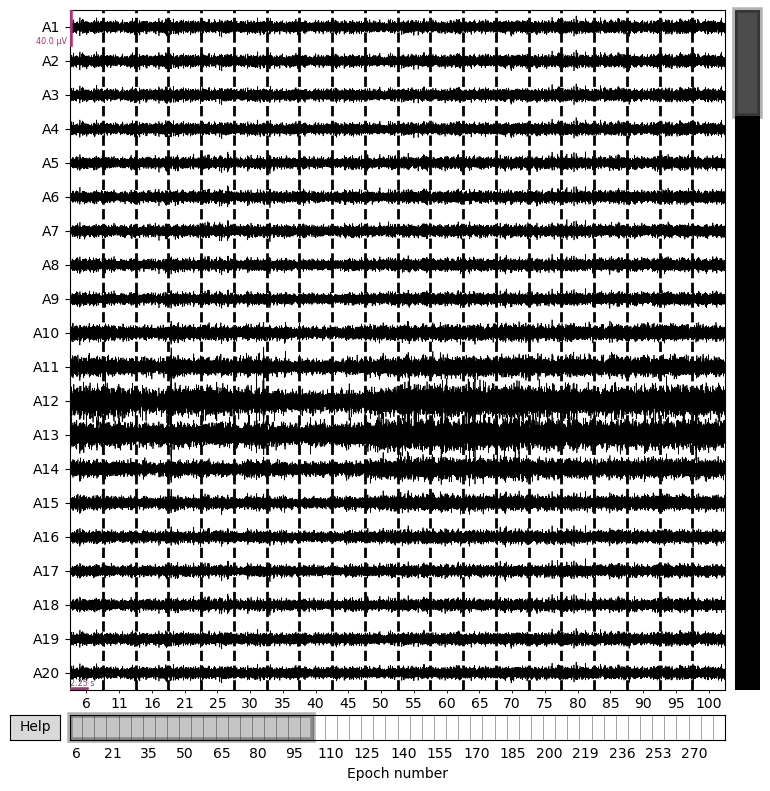

In [19]:
gamma_epochs.plot(title="Gamma Band (30 - 100 Hz)")

In [21]:
print(epochs.info)

<Info | 12 non-empty values
 bads: []
 ch_names: A1, A2, A3, A4, A5, A6, A7, A8, A9, A10, A11, A12, A13, A14, ...
 chs: 128 EEG, 1 Stimulus
 custom_ref_applied: True
 dig: 131 items (3 Cardinal, 128 EEG)
 file_id: 4 items (dict)
 highpass: 0.5 Hz
 lowpass: 100.0 Hz
 meas_date: 2019-08-20 10:57:41 UTC
 meas_id: 4 items (dict)
 nchan: 129
 projs: []
 sfreq: 254.0 Hz
 subject_info: <subject_info | >
>


In [23]:
# Load the BioSemi 128-channel montage
montage = mne.channels.make_standard_montage('biosemi128')

# Apply the montage to the epochs data
epochs.set_montage(montage)

<EpochsFIF | 54 events (all good), 0 – 4.5 s (baseline off), ~61.0 MiB, data loaded,
 'arriba': 12
 'abajo': 14
 'derecha': 11
 'izquierda': 17>

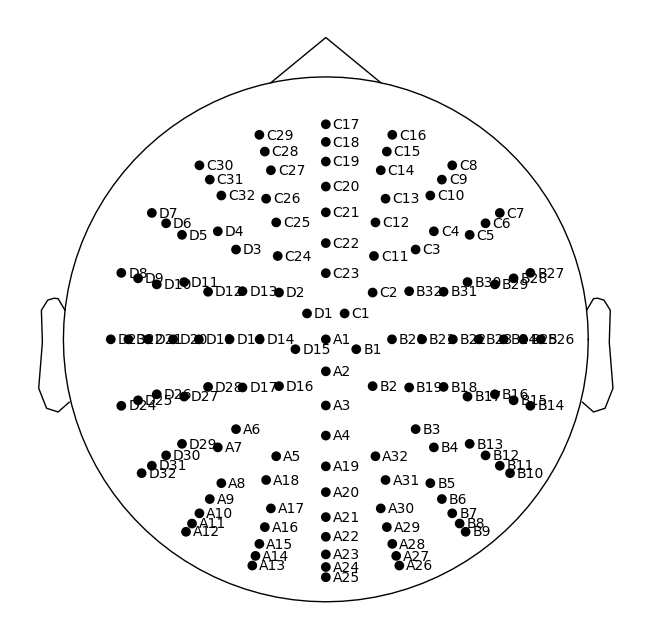

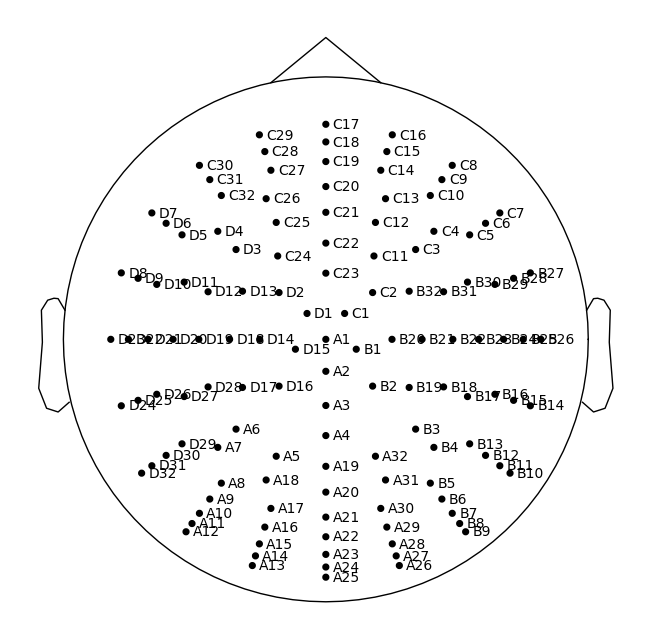

In [28]:
# 2D Montage Visualization
montage.plot()

In [31]:
import numpy as np
import mne
from scipy.signal import hilbert

# PLV 계산 함수
def compute_phase_difference(epochs, ch1, ch2):
    """
    두 채널 간의 위상 차이를 계산
    """
    # 각 채널의 데이터를 가져옵니다.
    data_ch1 = epochs.get_data()[:, epochs.info['ch_names'].index(ch1), :]
    data_ch2 = epochs.get_data()[:, epochs.info['ch_names'].index(ch2), :]
    
    # Hilbert transform을 이용하여 위상 정보를 얻음
    analytic_signal_ch1 = hilbert(data_ch1)
    analytic_signal_ch2 = hilbert(data_ch2)
    
    # 각 채널의 위상 계산
    phase_ch1 = np.angle(analytic_signal_ch1)
    phase_ch2 = np.angle(analytic_signal_ch2)
    
    # 두 채널 간의 위상 차이 계산
    phase_diff = phase_ch1 - phase_ch2
    
    return phase_diff

def compute_plv(phase_diff):
    """
    위상 차이를 기반으로 PLV를 계산합니다.
    """
    plv = np.abs(np.mean(np.exp(1j * phase_diff), axis=0))  # PLV 계산
    return plv

# 예시: 채널 2개 선택 (사용자가 선택)
ch1 = 'A1'  # 예시로 A1 채널 선택
ch2 = 'A2'  # 예시로 A2 채널 선택

# PLV 계산
phase_diff = compute_phase_difference(epochs, ch1, ch2)
plv = compute_plv(phase_diff)

print(f"PLV between {ch1} and {ch2}: {plv}")

PLV between A1 and A2: [0.9956212  0.99433043 0.99466766 ... 0.95905362 0.99223149 0.99682985]


In [41]:
import mne
import numpy as np
import matplotlib.pyplot as plt

# BioSemi 128채널 몽타주 로드
montage = mne.channels.make_standard_montage('biosemi128')

# 예시 epochs 데이터 (여기서는 dummy 데이터 사용)
# epochs = mne.read_epochs('your_epochs_data.fif')

# 채널 위치 (x, y 좌표) 가져오기
chan_pos = montage.get_positions()['ch_pos']

# PLV 계산 함수 (전체 채널 쌍에 대해 반복문)
def compute_all_plvs(epochs, channels):
    plv_matrix = np.zeros((len(channels), len(channels)))  # 채널 간 PLV를 저장할 행렬
    
    for i, ch1 in enumerate(channels):
        for j, ch2 in enumerate(channels):
            if i < j:
                # PLV 계산
                phase_diff = compute_phase_difference(epochs, ch1, ch2)
                plv = compute_plv(phase_diff)
                plv_matrix[i, j] = plv.mean()
                plv_matrix[j, i] = plv.mean()  # 대칭 행렬
    return plv_matrix

# 채널 리스트 (예시로 A1부터 A32까지 사용)
channels = ['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8', 'A9', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19', 'A20', 'A21', 'A22', 'A23', 'A24', 'A25', 'A26', 'A27', 'A28', 'A29', 'A30', 'A31', 'A32']

# PLV 계산
plv_matrix = compute_all_plvs(epochs, channels)

# PLV 값을 출력
print("PLV Matrix:")
print(plv_matrix)


PLV Matrix:
[[0.         0.99007234 0.98941301 ... 0.62952383 0.63073986 0.70810796]
 [0.99007234 0.         0.99120016 ... 0.64392247 0.64507907 0.71546728]
 [0.98941301 0.99120016 0.         ... 0.64852419 0.64970562 0.71826604]
 ...
 [0.62952383 0.64392247 0.64852419 ... 0.         0.99137343 0.77648412]
 [0.63073986 0.64507907 0.64970562 ... 0.99137343 0.         0.77417317]
 [0.70810796 0.71546728 0.71826604 ... 0.77648412 0.77417317 0.        ]]


<Figure size 800x800 with 0 Axes>

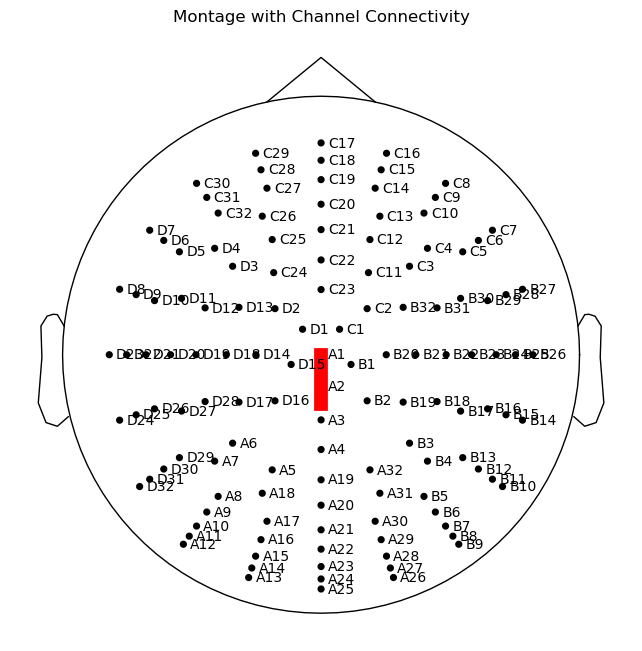

In [40]:
import mne
import numpy as np
import matplotlib.pyplot as plt

# BioSemi 128채널 몽타주 로드
montage = mne.channels.make_standard_montage('biosemi128')

# 예시 epochs 데이터 (여기서는 dummy 데이터 사용)
# epochs = mne.read_epochs('your_epochs_data.fif')

# 채널 위치 (x, y 좌표) 가져오기
chan_pos = montage.get_positions()['ch_pos']

# 예시로 A1과 A2 채널에 대한 PLV 계산
ch1 = 'A1'
ch2 = 'A2'

# PLV 계산 (예시로)
phase_diff = compute_phase_difference(epochs, ch1, ch2)
plv = compute_plv(phase_diff)

# PLV 값에 따라 연결선 그리기 (여기서는 0.9 이상만 연결선으로 표시)
threshold = 0.9
if plv.mean() > threshold:
    # 두 채널의 위치
    pos_ch1 = chan_pos[ch1]
    pos_ch2 = chan_pos[ch2]

    # 2D 시각화: 몽타주와 연결선
    plt.figure(figsize=(8, 8))
    
    # 몽타주 시각화
    montage.plot(show=False)  # show=False로 먼저 그려둔 후 추가 작업

    # 채널 간 연결선 그리기 (PLV 값에 따라 두께 또는 색상 설정)
    plt.plot([pos_ch1[0], pos_ch2[0]], [pos_ch1[1], pos_ch2[1]], 'r-', lw=plv.mean()*10)  # 선 두께는 PLV에 비례
    
    plt.title("Montage with Channel Connectivity")
    plt.show()


<Figure size 1000x1000 with 0 Axes>

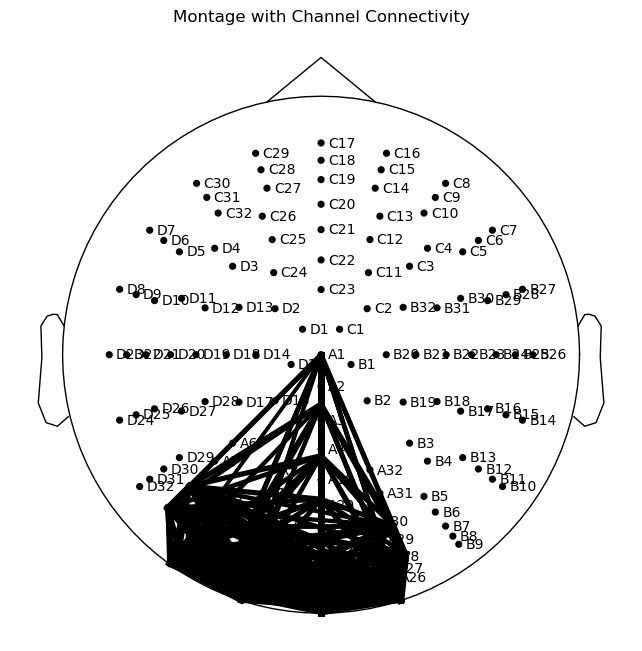

In [42]:
# 2D 시각화: 몽타주와 연결선
plt.figure(figsize=(10, 10))

# 몽타주 시각화
montage.plot(show=False)

# PLV 값에 따라 채널 간 연결선 그리기
threshold = 0.5  # 예시로 PLV가 0.5 이상인 경우만 연결선 그리기

for i, ch1 in enumerate(channels):
    for j, ch2 in enumerate(channels):
        if i < j:
            plv = plv_matrix[i, j]
            if plv > threshold:
                # 두 채널의 위치
                pos_ch1 = chan_pos[ch1]
                pos_ch2 = chan_pos[ch2]
                # 연결선 그리기 (PLV 값에 따라 선 두께 설정)
                linewidth = plv * 5  # PLV 값에 비례하여 선 두께 설정 (0~1 범위에서)
                plt.plot([pos_ch1[0], pos_ch2[0]], [pos_ch1[1], pos_ch2[1]], 'k-', lw=linewidth)

plt.title("Montage with Channel Connectivity")
plt.show()


In [ ]:
'''
cortical_regions = {
    "Broca and Wernicke's areas": 'Broca and Wernicke’s areas': ['AF3', 'F3', 'F5', 'FC3', 'FC5', 'T7', 'C5', 'TP7', 'CP5', 'P5'],
    "Visual cortex": ['POz', 'PO3', 'PO4', 'PO7', 'PO8', 'PO9', 'PO10', 'Oz', 'O1', 'O2'],
    "Auditory cortex": ['FT7', 'FT8', 'FT9', 'FT10', 'T7', 'T8', 'TP7', 'TP8', 'TP9', 'TP10'],
    "Motor cortex": ['Fz', 'F1', 'F2', 'F3', 'F4', 'FC1', 'FC2', 'FC3', 'FC4', 'Cz'],
    "Prefrontal cortex": ['Fp1', 'Fp2', 'AF3', 'AF4', 'AF7', 'AF8', 'F5', 'F6', 'F7', 'F8'],
    "Sensory cortex": ['Cz', 'C1', 'C2', 'C3', 'C4', 'CPz', 'CP1', 'CP2', 'CP3', 'CP4']   
}

# PLV 계산 함수
def compute_phase_difference(epochs, ch1, ch2):
    data_ch1 = epochs.get_data()[:, epochs.info['ch_names'].index(ch1), :]
    data_ch2 = epochs.get_data()[:, epochs.info['ch_names'].index(ch2), :]
    
    # Hilbert transform to get phase information
    analytic_signal_ch1 = mne.preprocessing.hilbert(data_ch1)
    analytic_signal_ch2 = mne.preprocessing.hilbert(data_ch2)
    
    # Calculate phase for each channel
    phase_ch1 = np.angle(analytic_signal_ch1)
    phase_ch2 = np.angle(analytic_signal_ch2)
    
    # Phase difference between channels
    phase_diff = phase_ch1 - phase_ch2
    
    return phase_diff
'''